# FedVocabHAR PAMAP2 Phase 4B

## Four-fold confirmatory validation of the locked ranked-MNN OpenFedHAR policy

This notebook performs the confirmatory independent-dataset experiment preregistered in Phase 3A. Every outer fold assigns two subjects to encoder training, two to checkpoint selection, two to vocabulary integration, and two to final testing. The ranked-MNN policy and its thresholds were locked in Phase 3D before PAMAP2 processing. The final test subjects are sealed until the SSL and Episodic Anchor checkpoints have been frozen.

The primary analysis uses forearm accelerometer XYZ plus magnitude. The notebook evaluates the SSL-Full initialization and the frozen Episodic Anchor adaptation, writes a checkpoint after every completed fold, and can resume after a Colab interruption.


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from dataclasses import dataclass,asdict
from pathlib import Path
from torch.autograd import Function
import copy,json,random,warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_recall_fscore_support,confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

@dataclass(frozen=True)
class Config:
    project:str='/content/drive/MyDrive/FedVocabHAR'
    seed:int=42
    known_activities:tuple=('lying','sitting','standing','walking')
    novel_activities:tuple=('ascending_stairs','descending_stairs','vacuum_cleaning','ironing')
    embedding_dim:int=64
    ssl_per_subject_activity:int=300
    probe_per_subject_activity:int=220
    integration_per_subject_activity:int=220
    batch_size:int=192
    ssl_epochs:int=20
    ssl_validation_every:int=4
    ssl_learning_rate:float=8e-4
    ssl_weight_decay:float=1e-4
    temperature:float=.12
    reconstruction_weight:float=.30
    domain_weight:float=.08
    variance_weight:float=.08
    mask_fraction:float=.25
    support_per_class:int=8
    query_per_class:int=12
    episodes_per_epoch:int=36
    episodic_epochs:int=20
    episodic_validation_every:int=2
    episodic_learning_rate:float=2e-4
    episodic_weight_decay:float=1e-5
    prototype_temperature:float=.10
    anchor_weight:float=.25
    known_accuracy_gate:float=.60
    known_macro_f1_gate:float=.50
    worst_known_f1_gate:float=.40
    novel_macro_f1_gate:float=.65
    worst_novel_f1_gate:float=.40
    combined_macro_f1_gate:float=.45
    cross_subject_sd_gate:float=.12

CFG=Config();PROJECT=Path(CFG.project);P4A=PROJECT/'artifacts'/'phase4a_fixed3';P3D=PROJECT/'artifacts'/'phase3d';OUT=PROJECT/'artifacts'/'phase4b';FOLD_DIR=OUT/'folds'
OUT.mkdir(parents=True,exist_ok=True);FOLD_DIR.mkdir(parents=True,exist_ok=True)
CACHE=PROJECT/'data'/'pamap2'/'cache'/'pamap2_hand_acc_common8_w128_s64_50hz.npz'
MANIFEST=P4A/'phase4a_preregistered_manifest.json';QUALITY=P4A/'phase4a_quality_decision.json';POLICY=P3D/'phase3d_policy_lock.json'
assert CACHE.exists() and MANIFEST.exists() and QUALITY.exists() and POLICY.exists()
manifest=json.loads(MANIFEST.read_text());quality=json.loads(QUALITY.read_text());policy_lock=json.loads(POLICY.read_text())
assert quality['proceed_to_phase4b'] and policy_lock['selected_policy']=='ranked_mnn' and tuple(manifest['known_activities'])==CFG.known_activities and tuple(manifest['novel_activities'])==CFG.novel_activities
folds=manifest['outer_folds'];assert len(folds)==4

def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu');seed_all(CFG.seed)
print('device:', DEVICE);print('PAMAP2 cache:', quality['cache']);print('PAMAP2 cache shape:', quality['cache_shape']);print(json.dumps(asdict(CFG), indent=2))


device: cuda
PAMAP2 cache: /content/drive/MyDrive/FedVocabHAR/data/pamap2/cache/pamap2_hand_acc_common8_w128_s64_50hz.npz
PAMAP2 cache shape: [11122, 4, 128]
{
  "project": "/content/drive/MyDrive/FedVocabHAR",
  "seed": 42,
  "known_activities": [
    "lying",
    "sitting",
    "standing",
    "walking"
  ],
  "novel_activities": [
    "ascending_stairs",
    "descending_stairs",
    "vacuum_cleaning",
    "ironing"
  ],
  "embedding_dim": 64,
  "ssl_per_subject_activity": 300,
  "probe_per_subject_activity": 220,
  "integration_per_subject_activity": 220,
  "batch_size": 192,
  "ssl_epochs": 20,
  "ssl_validation_every": 4,
  "ssl_learning_rate": 0.0008,
  "ssl_weight_decay": 0.0001,
  "temperature": 0.12,
  "reconstruction_weight": 0.3,
  "domain_weight": 0.08,
  "variance_weight": 0.08,
  "mask_fraction": 0.25,
  "support_per_class": 8,
  "query_per_class": 12,
  "episodes_per_epoch": 36,
  "episodic_epochs": 20,
  "episodic_validation_every": 2,
  "episodic_learning_rate": 0.0002

## Cache, architecture, and leakage guards

Normalization statistics are estimated independently inside each fold from encoder-training windows. SSL-Full sees only the four known activities from the six training subjects and never receives an activity label in its loss. Selection labels are used only for checkpoint scoring. Integration novel labels are opened only after the final encoder is frozen, to construct the expanded vocabulary prototypes.


In [3]:
d=np.load(CACHE);x=d['x'].astype(np.float32);subjects=d['subject'].astype(int);activities=d['activity'].astype(str)
all_activities=CFG.known_activities+CFG.novel_activities;known_to_index={a:i for i,a in enumerate(CFG.known_activities)};all_to_index={a:i for i,a in enumerate(all_activities)}
assert x.shape[1:]==(4,128) and set(np.unique(subjects))==set(range(101,109)) and set(np.unique(activities))==set(all_activities)

class InceptionBlock(nn.Module):
    def __init__(self,cin,width=32):
        super().__init__();self.bottleneck=nn.Conv1d(cin,width,1,bias=False)
        self.branches=nn.ModuleList([nn.Conv1d(width,width,k,padding=k//2,bias=False) for k in (9,19,39)])
        self.pool=nn.Sequential(nn.MaxPool1d(3,stride=1,padding=1),nn.Conv1d(cin,width,1,bias=False));self.bn=nn.BatchNorm1d(width*4)
    def forward(self,q):
        z=self.bottleneck(q);return F.relu(self.bn(torch.cat([b(z) for b in self.branches]+[self.pool(q)],1)))

class InceptionEncoder(nn.Module):
    def __init__(self,cin,dim,n_domains):
        super().__init__();self.block1=InceptionBlock(cin,32);self.block2=InceptionBlock(128,32)
        self.skip=nn.Conv1d(cin,128,1,bias=False);self.bn=nn.BatchNorm1d(128)
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,dim))
        self.decoder=nn.Conv1d(128,cin,1);self.domain=nn.Sequential(nn.Linear(dim,64),nn.ReLU(),nn.Linear(64,n_domains))
    def sequence(self,q):return F.relu(self.bn(self.block2(self.block1(q))+self.skip(q)))
    def forward(self,q,return_sequence=False):
        seq=self.sequence(q);emb=F.normalize(self.project(seq.mean(-1)),dim=1);return (emb,seq) if return_sequence else emb

class GradientReverse(Function):
    @staticmethod
    def forward(ctx,q,lambd):ctx.lambd=lambd;return q.view_as(q)
    @staticmethod
    def backward(ctx,grad):return -ctx.lambd*grad,None

def safe_load(path):
    try:return torch.load(path,map_location='cpu',weights_only=False)
    except TypeError:return torch.load(path,map_location='cpu')

def encode(model,data,batch=512):
    out=[];model.eval()
    with torch.no_grad():
        for start in range(0,len(data),batch):out.append(model(torch.from_numpy(data[start:start+batch]).to(DEVICE)).cpu().numpy())
    return np.concatenate(out).astype(np.float32)

def limited_by_group(subject_set,activity_set,per_group,seed):
    rng=np.random.default_rng(seed);out=[]
    for subject in subject_set:
        for activity in activity_set:
            idx=np.where((subjects==subject)&(activities==activity))[0]
            if len(idx)>per_group:idx=rng.choice(idx,per_group,replace=False)
            out.extend(idx.tolist())
    return np.asarray(out,dtype=int)

def unit(z):return z/(np.linalg.norm(z,axis=1,keepdims=True)+1e-12)

def metric_bundle(true,pred,labels):
    f1=precision_recall_fscore_support(true,pred,labels=labels,zero_division=0)[2]
    return {'accuracy':float(accuracy_score(true,pred)),'macro_f1':float(np.mean(f1)),'per_class_f1':f1}

def linear_eval(train_e,train_y,test_e,test_y,labels):
    pipe=Pipeline([('scale',StandardScaler()),('lr',LogisticRegression(max_iter=1800,class_weight='balanced',random_state=CFG.seed))])
    pipe.fit(train_e,train_y);pred=pipe.predict(test_e);return metric_bundle(test_y,pred,labels)|{'pred':pred}

def prototype_eval(train_e,train_y,test_e,test_y,labels):
    scaler=StandardScaler().fit(train_e);tr=unit(scaler.transform(train_e));te=unit(scaler.transform(test_e))
    prototypes=np.asarray([unit(tr[train_y==label].mean(0,keepdims=True))[0] for label in labels]);pred=np.asarray(labels)[(te@prototypes.T).argmax(1)]
    return metric_bundle(test_y,pred,labels)|{'pred':pred}

print('cache loaded:',x.shape)


cache loaded: (11122, 4, 128)


## Fold-local SSL-Full training

The fixed SSL-Full objective combines sensor-aware NT-Xent contrastive learning, embedding-variance regularization, masked reconstruction, and gradient-reversal subject invariance. No candidate search occurs in Phase 4B. The best epoch is selected solely by known-activity prototype transfer to the three selection subjects.


In [4]:
def ntxent(z1,z2,temp):
    z=torch.cat([z1,z2],0);sim=z@z.T/temp;n=len(z1);eye=torch.eye(2*n,dtype=torch.bool,device=z.device)
    sim=sim.masked_fill(eye,-1e9);target=torch.cat([torch.arange(n,2*n,device=z.device),torch.arange(n,device=z.device)])
    return F.cross_entropy(sim,target)

def variance_loss(z):return F.relu(1-torch.sqrt(z.var(0)+1e-4)).mean()

def random_rotation(batch):
    q=torch.randn(batch,4,device=DEVICE);q=F.normalize(q,dim=1);w,a,b,c=q.unbind(1)
    return torch.stack([1-2*(b*b+c*c),2*(a*b-c*w),2*(a*c+b*w),2*(a*b+c*w),1-2*(a*a+c*c),2*(b*c-a*w),2*(a*c-b*w),2*(b*c+a*w),1-2*(a*a+b*b)],1).view(batch,3,3)

def make_inputs(raw,stats):
    xyz=(raw[:,:3]-stats['xyz_mean'])/stats['xyz_std'];mag=(raw[:,3:4]-stats['mag_mean'])/stats['mag_std']
    return np.concatenate([xyz,mag],1).astype(np.float32)

def sensor_view(raw,stats,strong=True):
    q=raw[:,:3].clone();q=torch.bmm(random_rotation(len(q)),q);q=q*(1+torch.randn(len(q),1,1,device=q.device)*(.12 if strong else .06));q=q+torch.randn_like(q)*(.035 if strong else .02)
    shifts=torch.randint(-8 if strong else -4,9 if strong else 5,(len(q),),device=q.device);time=(torch.arange(q.size(-1),device=q.device)[None,:]-shifts[:,None])%q.size(-1)
    q=torch.gather(q,2,time[:,None,:].expand(-1,3,-1))
    if strong:
        length=q.size(-1);keep=int(torch.randint(int(.82*length),length+1,(1,),device=q.device).item());start=int(torch.randint(0,length-keep+1,(1,),device=q.device).item())
        q=F.interpolate(q[:,:,start:start+keep],size=length,mode='linear',align_corners=False)
    xyz=(q-torch.as_tensor(stats['xyz_mean'],device=q.device))/torch.as_tensor(stats['xyz_std'],device=q.device)
    mag=torch.sqrt((q*q).sum(1,keepdim=True)+1e-8);mag=(mag-torch.as_tensor(stats['mag_mean'],device=q.device))/torch.as_tensor(stats['mag_std'],device=q.device)
    return torch.cat([xyz,mag],1)

def selection_diagnostics(model,model_input,train_subjects,selection_subjects,seed):
    tr_idx=limited_by_group(train_subjects,CFG.known_activities,CFG.probe_per_subject_activity,seed);te_idx=limited_by_group(selection_subjects,CFG.known_activities,CFG.probe_per_subject_activity,seed+1)
    tr=encode(model,model_input[tr_idx]);te=encode(model,model_input[te_idx]);train_y=np.asarray([known_to_index[a] for a in activities[tr_idx]]);rows=[]
    for held in selection_subjects:
        q=subjects[te_idx]==held;true=np.asarray([known_to_index[a] for a in activities[te_idx[q]]]);m=prototype_eval(tr,train_y,te[q],true,list(range(len(CFG.known_activities))))
        rows.append({'subject':held,'prototype_accuracy':m['accuracy'],'prototype_macro_f1':m['macro_f1'],'worst_class_f1':float(np.min(m['per_class_f1']))})
    frame=pd.DataFrame(rows);summary={'prototype_accuracy':frame.prototype_accuracy.mean(),'prototype_macro_f1':frame.prototype_macro_f1.mean(),'prototype_macro_f1_std':frame.prototype_macro_f1.std(ddof=0),'worst_class_f1':frame.worst_class_f1.mean()}
    summary['selection_score']=summary['prototype_macro_f1']+.20*summary['worst_class_f1']-.10*summary['prototype_macro_f1_std'];return frame,summary

def train_ssl(fold_id,train_subjects,selection_subjects,stats,model_input):
    seed=CFG.seed+100*fold_id;seed_all(seed);ssl_idx=limited_by_group(train_subjects,CFG.known_activities,CFG.ssl_per_subject_activity,seed)
    subject_to_domain={s:i for i,s in enumerate(train_subjects)};model=InceptionEncoder(4,CFG.embedding_dim,len(train_subjects)).to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=CFG.ssl_learning_rate,weight_decay=CFG.ssl_weight_decay);rng=np.random.default_rng(seed);best=-1e9;history=[];selection_rows=[]
    for epoch in range(1,CFG.ssl_epochs+1):
        model.train();losses=[];order=rng.permutation(ssl_idx)
        for start in range(0,len(order),CFG.batch_size):
            idx=order[start:start+CFG.batch_size]
            if len(idx)<16:continue
            raw=torch.from_numpy(x[idx]).to(DEVICE);v1=sensor_view(raw,stats,True);v2=sensor_view(raw,stats,True);opt.zero_grad();z1=model(v1);z2=model(v2)
            loss=ntxent(z1,z2,CFG.temperature)+CFG.variance_weight*(variance_loss(z1)+variance_loss(z2))
            domains=torch.tensor([subject_to_domain[int(s)] for s in subjects[idx]],device=DEVICE)
            loss=loss+CFG.domain_weight*F.cross_entropy(model.domain(GradientReverse.apply((z1+z2)/2,1.0)),domains)
            clean=sensor_view(raw,stats,False);masked=clean.clone();length=max(1,int(clean.size(-1)*CFG.mask_fraction));starts=torch.randint(0,clean.size(-1)-length+1,(len(clean),),device=DEVICE)
            timeline=torch.arange(clean.size(-1),device=DEVICE)[None,:];time_mask=(timeline>=starts[:,None])&(timeline<(starts+length)[:,None]);masked=masked.masked_fill(time_mask[:,None,:],0)
            _,seq=model(masked,True);recon=model.decoder(seq);mask=time_mask[:,None,:].expand_as(clean).to(clean.dtype);rec=((recon-clean).pow(2)*mask).sum()/mask.sum().clamp_min(1)
            loss=loss+CFG.reconstruction_weight*rec;loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),5.0);opt.step();losses.append(float(loss.detach().cpu()))
        row={'fold':fold_id,'stage':'ssl','epoch':epoch,'loss':float(np.mean(losses))}
        if epoch%CFG.ssl_validation_every==0 or epoch==CFG.ssl_epochs:
            detail,summary=selection_diagnostics(model,model_input,train_subjects,selection_subjects,CFG.seed+1000*fold_id);row.update(summary);detail['fold']=fold_id;detail['stage']='ssl';detail['epoch']=epoch;selection_rows.extend(detail.to_dict('records'))
            if summary['selection_score']>best:best=summary['selection_score'];best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()};best_epoch=epoch;best_summary=summary.copy()
            print('fold',fold_id,'SSL epoch',epoch,'loss',round(row['loss'],4),'selection F1',round(summary['prototype_macro_f1'],4))
        history.append(row)
    model.load_state_dict(best_state);model.eval();return model,history,selection_rows,{'best_epoch':best_epoch,**best_summary}


## Frozen Episodic Anchor adaptation

Cross-subject episodes use known activities from encoder-training subjects. For each activity, support and query examples come from different subjects. The fixed anchor penalty of 0.25 preserves the SSL-Full geometry. The checkpoint is again selected only on the three selection subjects.


In [5]:
def train_episodic(fold_id,ssl_model,train_subjects,selection_subjects,model_input):
    seed=CFG.seed+100*fold_id+17;seed_all(seed);anchor=copy.deepcopy(ssl_model).to(DEVICE).eval()
    for p in anchor.parameters():p.requires_grad=False
    model=copy.deepcopy(ssl_model).to(DEVICE);opt=torch.optim.AdamW(model.parameters(),lr=CFG.episodic_learning_rate,weight_decay=CFG.episodic_weight_decay);rng=np.random.default_rng(seed)
    lookup={(a,s):np.where((activities==a)&(subjects==s))[0] for a in CFG.known_activities for s in train_subjects};best=-1e9;history=[];selection_rows=[]
    for epoch in range(1,CFG.episodic_epochs+1):
        model.train();losses=[]
        for _ in range(CFG.episodes_per_epoch):
            si=[];qi=[];sy=[];qy=[]
            for label,activity in enumerate(CFG.known_activities):
                ss,qs=rng.choice(train_subjects,2,replace=False);sidx=lookup[(activity,int(ss))];qidx=lookup[(activity,int(qs))]
                si.extend(rng.choice(sidx,CFG.support_per_class,replace=len(sidx)<CFG.support_per_class));qi.extend(rng.choice(qidx,CFG.query_per_class,replace=len(qidx)<CFG.query_per_class));sy.extend([label]*CFG.support_per_class);qy.extend([label]*CFG.query_per_class)
            sx=torch.from_numpy(model_input[np.asarray(si)]).to(DEVICE);qx=torch.from_numpy(model_input[np.asarray(qi)]).to(DEVICE);sy=torch.tensor(sy,device=DEVICE);qy=torch.tensor(qy,device=DEVICE)
            opt.zero_grad();zs=model(sx);zq=model(qx);prototypes=torch.stack([F.normalize(zs[sy==label].mean(0),dim=0) for label in range(len(CFG.known_activities))]);loss=F.cross_entropy(zq@prototypes.T/CFG.prototype_temperature,qy)
            with torch.no_grad():anchor_z=torch.cat([anchor(sx),anchor(qx)],0)
            current=torch.cat([zs,zq],0);loss=loss+CFG.anchor_weight*(1-(current*anchor_z).sum(1)).mean();loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),5.0);opt.step();losses.append(float(loss.detach().cpu()))
        row={'fold':fold_id,'stage':'episodic_anchor','epoch':epoch,'loss':float(np.mean(losses))}
        if epoch%CFG.episodic_validation_every==0 or epoch==CFG.episodic_epochs:
            detail,summary=selection_diagnostics(model,model_input,train_subjects,selection_subjects,CFG.seed+1000*fold_id);row.update(summary);detail['fold']=fold_id;detail['stage']='episodic_anchor';detail['epoch']=epoch;selection_rows.extend(detail.to_dict('records'))
            if summary['selection_score']>best:best=summary['selection_score'];best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()};best_epoch=epoch;best_summary=summary.copy()
            print('fold',fold_id,'anchor epoch',epoch,'loss',round(row['loss'],4),'selection F1',round(summary['prototype_macro_f1'],4))
        history.append(row)
    model.load_state_dict(best_state);model.eval();return model,history,selection_rows,{'best_epoch':best_epoch,**best_summary}


## Resumable five-fold training and sealed evaluation

A completed fold is saved as one checkpoint bundle and one JSON record. Rerunning this cell skips completed folds. Test labels are accessed only inside `evaluate_frozen`, after both checkpoints and normalization statistics are fixed.


In [6]:
def evaluate_frozen(fold_id,stage,model,model_input,train_subjects,selection_subjects,integration_subjects,test_subjects):
    known_train=limited_by_group(tuple(train_subjects)+tuple(selection_subjects),CFG.known_activities,CFG.probe_per_subject_activity,CFG.seed+fold_id+500)
    novel_train=limited_by_group(integration_subjects,CFG.novel_activities,CFG.integration_per_subject_activity,CFG.seed+fold_id+600)
    test_known=np.where(np.isin(subjects,test_subjects)&np.isin(activities,CFG.known_activities))[0];test_novel=np.where(np.isin(subjects,test_subjects)&np.isin(activities,CFG.novel_activities))[0]
    embedding=encode(model,model_input);known_y=np.asarray([known_to_index[a] for a in activities[known_train]]);test_known_y=np.asarray([known_to_index[a] for a in activities[test_known]])
    oracle_train=np.concatenate([known_train,novel_train]);oracle_y=np.asarray([all_to_index[a] for a in activities[oracle_train]]);test_all=np.concatenate([test_known,test_novel]);test_all_y=np.asarray([all_to_index[a] for a in activities[test_all]])
    linear=linear_eval(embedding[known_train],known_y,embedding[test_known],test_known_y,list(range(len(CFG.known_activities))))
    known=prototype_eval(embedding[known_train],known_y,embedding[test_known],test_known_y,list(range(len(CFG.known_activities))))
    combined=prototype_eval(embedding[oracle_train],oracle_y,embedding[test_all],test_all_y,list(range(len(all_activities))))
    novel_true=test_all_y[len(test_known):];novel_pred=combined['pred'][len(test_known):];novel_labels=[all_to_index[a] for a in CFG.novel_activities];novel=metric_bundle(novel_true,novel_pred,novel_labels)
    summary={'fold':fold_id,'stage':stage,'linear_known_accuracy':linear['accuracy'],'linear_known_macro_f1':linear['macro_f1'],'prototype_known_accuracy':known['accuracy'],'prototype_known_macro_f1':known['macro_f1'],'prototype_worst_known_f1':float(np.min(known['per_class_f1'])),'prototype_novel_macro_f1':novel['macro_f1'],'prototype_worst_novel_f1':float(np.min(novel['per_class_f1'])),'prototype_combined_macro_f1':combined['macro_f1']}
    class_rows=[]
    for a,f in zip(CFG.known_activities,known['per_class_f1']):class_rows.append({'fold':fold_id,'stage':stage,'group':'known','activity':a,'f1':float(f)})
    for a,f in zip(CFG.novel_activities,novel['per_class_f1']):class_rows.append({'fold':fold_id,'stage':stage,'group':'novel','activity':a,'f1':float(f)})
    subject_rows=[]
    for held in test_subjects:
        hk=test_known[subjects[test_known]==held];hn=test_novel[subjects[test_novel]==held];ha=np.concatenate([hk,hn]);ky=np.asarray([known_to_index[a] for a in activities[hk]]);ay=np.asarray([all_to_index[a] for a in activities[ha]])
        km=prototype_eval(embedding[known_train],known_y,embedding[hk],ky,list(range(len(CFG.known_activities))));am=prototype_eval(embedding[oracle_train],oracle_y,embedding[ha],ay,list(range(len(all_activities))))
        available=metric_bundle(ay,am['pred'],sorted(np.unique(ay).tolist()))
        subject_rows.append({'fold':fold_id,'stage':stage,'subject':int(held),'available_activities':int(len(np.unique(ay))),'known_macro_f1':km['macro_f1'],'combined_macro_f1':available['macro_f1']})
    cm=confusion_matrix(test_all_y,combined['pred'],labels=list(range(len(all_activities))));conf_rows=[]
    for i,t in enumerate(all_activities):
        for j,p in enumerate(all_activities):conf_rows.append({'fold':fold_id,'stage':stage,'true_activity':t,'predicted_activity':p,'count':int(cm[i,j])})
    return summary,class_rows,subject_rows,conf_rows

for fold in folds:
    fold_id = int(fold['fold'])
    complete = FOLD_DIR / f'fold_{fold_id}_complete.json'
    checkpoint = FOLD_DIR / f'fold_{fold_id}_models.pt'
    if complete.exists() and checkpoint.exists():
        print('fold', fold_id, 'already complete; skipping')
        continue

    train_subjects = tuple(fold['train_subjects'])
    selection_subjects = tuple(fold['selection_subjects'])
    integration_subjects = tuple(fold['integration_subjects'])
    test_subjects = tuple(fold['test_subjects'])
    roles = [set(train_subjects), set(selection_subjects), set(integration_subjects), set(test_subjects)]
    assert all(roles[i].isdisjoint(roles[j]) for i in range(4) for j in range(i + 1, 4))
    assert set.union(*roles) == set(range(101, 109))

    stat_idx = np.where(np.isin(subjects, train_subjects) & np.isin(activities, CFG.known_activities))[0]
    raw = x[stat_idx]
    stats = {
        'xyz_mean': raw[:, :3].mean((0, 2), keepdims=True).astype(np.float32),
        'xyz_std': (raw[:, :3].std((0, 2), keepdims=True) + 1e-6).astype(np.float32),
        'mag_mean': raw[:, 3:4].mean((0, 2), keepdims=True).astype(np.float32),
        'mag_std': (raw[:, 3:4].std((0, 2), keepdims=True) + 1e-6).astype(np.float32),
    }
    model_input = make_inputs(x, stats)
    ssl_model, ssl_history, ssl_selection, ssl_best = train_ssl(fold_id, train_subjects, selection_subjects, stats, model_input)
    anchor_model, anchor_history, anchor_selection, anchor_best = train_episodic(fold_id, ssl_model, train_subjects, selection_subjects, model_input)
    fold_results, class_rows, subject_rows, conf_rows = [], [], [], []
    for stage, model in [('ssl_full', ssl_model), ('episodic_anchor', anchor_model)]:
        summary, cr, sr, cfr = evaluate_frozen(fold_id, stage, model, model_input, train_subjects, selection_subjects, integration_subjects, test_subjects)
        fold_results.append(summary); class_rows += cr; subject_rows += sr; conf_rows += cfr
    torch.save({'fold': fold, 'config': asdict(CFG), 'stats': stats, 'ssl_state_dict': {k:v.cpu() for k,v in ssl_model.state_dict().items()}, 'anchor_state_dict': {k:v.cpu() for k,v in anchor_model.state_dict().items()}, 'ssl_selection': ssl_best, 'anchor_selection': anchor_best}, checkpoint)
    payload = {'fold': fold_id, 'roles': fold, 'ssl_selection': ssl_best, 'anchor_selection': anchor_best, 'results': fold_results, 'history': ssl_history + anchor_history, 'selection_subjects': ssl_selection + anchor_selection, 'per_class': class_rows, 'per_subject': subject_rows, 'confusions': conf_rows}
    complete.write_text(json.dumps(payload, indent=2))
    print('completed fold', fold_id)
    torch.cuda.empty_cache()


fold 1 SSL epoch 4 loss 5.6308 selection F1 0.8617
fold 1 SSL epoch 8 loss 5.4598 selection F1 0.8612
fold 1 SSL epoch 12 loss 5.4215 selection F1 0.8855
fold 1 SSL epoch 16 loss 5.2435 selection F1 0.8866
fold 1 SSL epoch 20 loss 5.0996 selection F1 0.855
fold 1 anchor epoch 2 loss 0.3154 selection F1 0.9001
fold 1 anchor epoch 4 loss 0.2701 selection F1 0.9017
fold 1 anchor epoch 6 loss 0.2159 selection F1 0.9241
fold 1 anchor epoch 8 loss 0.2204 selection F1 0.8892
fold 1 anchor epoch 10 loss 0.1799 selection F1 0.9124
fold 1 anchor epoch 12 loss 0.1708 selection F1 0.9033
fold 1 anchor epoch 14 loss 0.1521 selection F1 0.9169
fold 1 anchor epoch 16 loss 0.1199 selection F1 0.8941
fold 1 anchor epoch 18 loss 0.1619 selection F1 0.8977
fold 1 anchor epoch 20 loss 0.1507 selection F1 0.8696
completed fold 1
fold 2 SSL epoch 4 loss 5.6724 selection F1 0.7361
fold 2 SSL epoch 8 loss 5.4581 selection F1 0.7401
fold 2 SSL epoch 12 loss 5.3298 selection F1 0.6973
fold 2 SSL epoch 16 loss 5

## Aggregate results, gates, and confirmatory decision

The primary model is Episodic Anchor. Gates are applied to the mean fold metrics, the lowest mean activity F1, and the standard deviation across the 15 held-out subjects. SSL-Full remains a fixed ablation and is not used to select or revise the primary model.


In [7]:
assert all((FOLD_DIR/f'fold_{i}_complete.json').exists() for i in range(1,5)),'Not all folds completed; rerun the previous cell to resume'
payloads=[json.loads((FOLD_DIR/f'fold_{i}_complete.json').read_text()) for i in range(1,5)]
results=pd.DataFrame([r for p in payloads for r in p['results']]);history=pd.DataFrame([r for p in payloads for r in p['history']]);selection_subjects=pd.DataFrame([r for p in payloads for r in p['selection_subjects']]);per_class=pd.DataFrame([r for p in payloads for r in p['per_class']]);per_subject=pd.DataFrame([r for p in payloads for r in p['per_subject']]);confusions=pd.DataFrame([r for p in payloads for r in p['confusions']])
results.to_csv(OUT/'phase4b_fold_results.csv',index=False);history.to_csv(OUT/'phase4b_training_history.csv',index=False);selection_subjects.to_csv(OUT/'phase4b_selection_subjects.csv',index=False);per_class.to_csv(OUT/'phase4b_per_class_f1.csv',index=False);per_subject.to_csv(OUT/'phase4b_test_subjects.csv',index=False);confusions.to_csv(OUT/'phase4b_confusions.csv',index=False)
primary=results[results.stage=='episodic_anchor'];ssl=results[results.stage=='ssl_full'];primary_class=per_class[per_class.stage=='episodic_anchor'];primary_subject=per_subject[per_subject.stage=='episodic_anchor']
means=primary.mean(numeric_only=True);known_activity_means=primary_class[primary_class.group=='known'].groupby('activity').f1.mean();novel_activity_means=primary_class[primary_class.group=='novel'].groupby('activity').f1.mean()
subject_sd=float(primary_subject.groupby('subject').combined_macro_f1.mean().std(ddof=0))
gates={'G1_all_five_folds_complete':len(primary)==5,'G2_test_subjects_sealed_and_disjoint':len(primary_subject.subject.unique())==15,'G3_linear_known_accuracy':bool(means.linear_known_accuracy>=CFG.known_accuracy_gate),'G4_prototype_known_macro_f1':bool(means.prototype_known_macro_f1>=CFG.known_macro_f1_gate),'G5_worst_known_activity_f1':bool(known_activity_means.min()>=CFG.worst_known_f1_gate),'G6_prototype_novel_macro_f1':bool(means.prototype_novel_macro_f1>=CFG.novel_macro_f1_gate),'G7_worst_novel_activity_f1':bool(novel_activity_means.min()>=CFG.worst_novel_f1_gate),'G8_prototype_combined_macro_f1':bool(means.prototype_combined_macro_f1>=CFG.combined_macro_f1_gate),'G9_cross_subject_stability':bool(subject_sd<=CFG.cross_subject_sd_gate),'G10_all_artifacts_complete':bool(len(results)==10 and len(per_class)==80 and len(per_subject)==30)}
confirmatory_pass=bool(all(gates.values()))

def native(v):
    if isinstance(v,(np.bool_,bool)):return bool(v)
    if isinstance(v,(np.floating,float)):return float(v)
    if isinstance(v,(np.integer,int)):return int(v)
    return v

decision={'phase':'Phase 4B','dataset':'RealWorld HAR','primary_model':'episodic_anchor','confirmatory_pass':confirmatory_pass,'gates':gates,'primary_mean_results':{k:native(v) for k,v in means.to_dict().items()},'ssl_mean_results':{k:native(v) for k,v in ssl.mean(numeric_only=True).to_dict().items()},'known_activity_mean_f1':{k:float(v) for k,v in known_activity_means.items()},'novel_activity_mean_f1':{k:float(v) for k,v in novel_activity_means.items()},'cross_subject_combined_macro_f1_sd':subject_sd,'expected_dataset_omission':'subject 2 climbing-up has no official forearm recording','interpretation':'Independent confirmatory evaluation. No Phase 4B test result may be used to retune the frozen method or gates.','config':asdict(CFG)}
(OUT/'phase4b_decision.json').write_text(json.dumps(decision,indent=2));display(results.round(4));print(json.dumps(decision,indent=2))


,fold,stage,linear_known_accuracy,linear_known_macro_f1,prototype_known_accuracy,prototype_known_macro_f1,prototype_worst_known_f1,prototype_novel_macro_f1,prototype_worst_novel_f1,prototype_combined_macro_f1
0,1,ssl_full,0.6834,0.6670,0.6658,0.6476,0.4218,0.5302,0.4072,0.4321
1,1,episodic_anchor,0.6769,0.6645,0.6938,0.6808,0.4444,0.3048,0.1212,0.3828
2,2,ssl_full,0.8782,0.8720,0.8512,0.8519,0.8010,0.3646,0.1327,0.4702
3,2,episodic_anchor,0.8486,0.8425,0.8892,0.8883,0.8376,0.3674,0.1657,0.4900
4,3,ssl_full,0.9143,0.9079,0.8012,0.7759,0.5757,0.5488,0.3961,0.4932
5,3,episodic_anchor,0.8509,0.8306,0.8528,0.8322,0.6847,0.5102,0.4189,0.5877
6,4,ssl_full,0.8185,0.8045,0.8494,0.8403,0.7643,0.4700,0.3567,0.5013
7,4,episodic_anchor,0.4554,0.4395,0.6444,0.6536,0.5595,0.3121,0.1639,0.4023


{
  "phase": "Phase 4B",
  "dataset": "RealWorld HAR",
  "primary_model": "episodic_anchor",
  "confirmatory_pass": false,
  "gates": {
    "G1_all_five_folds_complete": false,
    "G2_test_subjects_sealed_and_disjoint": false,
    "G3_linear_known_accuracy": true,
    "G4_prototype_known_macro_f1": true,
    "G5_worst_known_activity_f1": true,
    "G6_prototype_novel_macro_f1": false,
    "G7_worst_novel_activity_f1": false,
    "G8_prototype_combined_macro_f1": true,
    "G9_cross_subject_stability": false,
    "G10_all_artifacts_complete": false
  },
  "primary_mean_results": {
    "fold": 2.5,
    "linear_known_accuracy": 0.7079271986839226,
    "linear_known_macro_f1": 0.6942558069171241,
    "prototype_known_accuracy": 0.7700350539632477,
    "prototype_known_macro_f1": 0.7637192356829593,
    "prototype_worst_known_f1": 0.6315840190558761,
    "prototype_novel_macro_f1": 0.3736113389360555,
    "prototype_worst_novel_f1": 0.2174449380187085,
    "prototype_combined_macro_f1": 0.

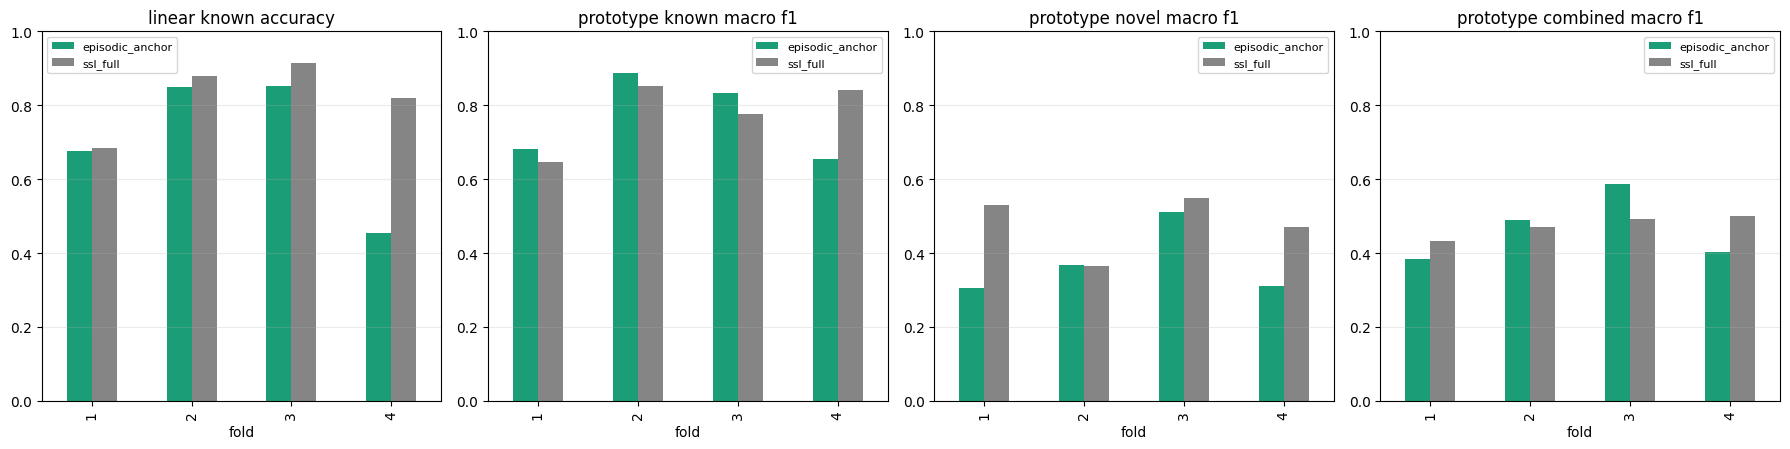

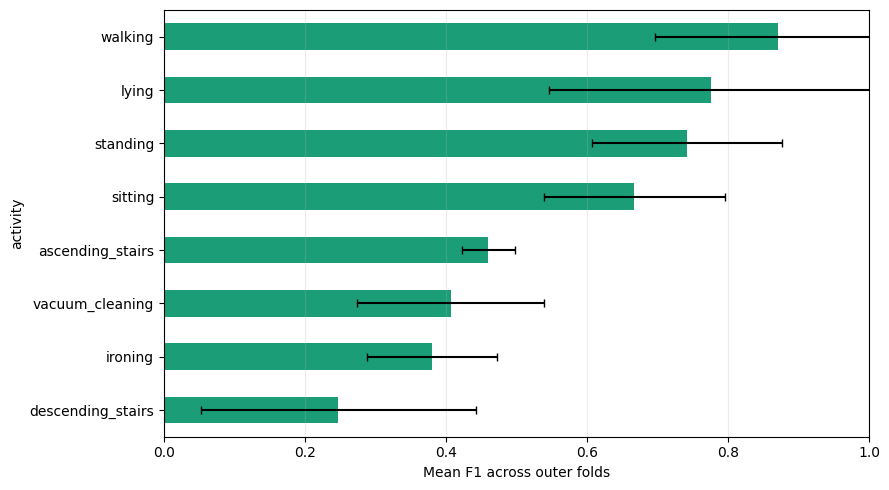

# FedVocabHAR RealWorld Phase 4B Confirmatory Report

## Decision

**Confirmatory gates passed:** False

## Primary Episodic Anchor results

- Linear known accuracy: 0.7079
- Prototype known macro-F1: 0.7637
- Worst known activity mean F1: 0.6671
- Prototype novel macro-F1: 0.3736
- Worst novel activity mean F1: 0.2472
- Prototype combined macro-F1: 0.4657
- Cross-subject combined macro-F1 SD: 0.1353

## Frozen SSL-Full ablation

- Prototype known macro-F1: 0.7789
- Prototype novel macro-F1: 0.4784
- Prototype combined macro-F1: 0.4742

## Gates

- G1_all_five_folds_complete: **False**
- G2_test_subjects_sealed_and_disjoint: **False**
- G3_linear_known_accuracy: **True**
- G4_prototype_known_macro_f1: **True**
- G5_worst_known_activity_f1: **True**
- G6_prototype_novel_macro_f1: **False**
- G7_worst_novel_activity_f1: **False**
- G8_prototype_combined_macro_f1: **True**
- G9_cross_subject_stability: **False**
- G10_all_artifacts_complete: **False**

Subject 2 climbing-up is absent beca

In [8]:
metric_names=['linear_known_accuracy','prototype_known_macro_f1','prototype_novel_macro_f1','prototype_combined_macro_f1'];summary=results.groupby('stage')[metric_names].agg(['mean','std'])
fig,axes=plt.subplots(1,4,figsize=(18,4.6))
for ax,metric in zip(axes,metric_names):
    table=results.pivot(index='fold',columns='stage',values=metric);table.plot(kind='bar',ax=ax,color=['#1b9e77','#858585']);ax.set_title(metric.replace('_',' '));ax.set_ylim(0,1);ax.grid(axis='y',alpha=.25);ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'phase4b_fold_comparison.png',dpi=180,bbox_inches='tight');plt.show()

activity_table=primary_class.pivot_table(index='activity',columns='fold',values='f1');fig,ax=plt.subplots(figsize=(9,5));activity_table.mean(1).sort_values().plot(kind='barh',xerr=activity_table.std(1),ax=ax,color='#1b9e77',capsize=3);ax.set_xlim(0,1);ax.set_xlabel('Mean F1 across outer folds');ax.grid(axis='x',alpha=.25);fig.tight_layout();fig.savefig(OUT/'phase4b_activity_f1.png',dpi=180,bbox_inches='tight');plt.show()

report=f"""# FedVocabHAR RealWorld Phase 4B Confirmatory Report

## Decision

**Confirmatory gates passed:** {confirmatory_pass}

## Primary Episodic Anchor results

- Linear known accuracy: {means.linear_known_accuracy:.4f}
- Prototype known macro-F1: {means.prototype_known_macro_f1:.4f}
- Worst known activity mean F1: {known_activity_means.min():.4f}
- Prototype novel macro-F1: {means.prototype_novel_macro_f1:.4f}
- Worst novel activity mean F1: {novel_activity_means.min():.4f}
- Prototype combined macro-F1: {means.prototype_combined_macro_f1:.4f}
- Cross-subject combined macro-F1 SD: {subject_sd:.4f}

## Frozen SSL-Full ablation

- Prototype known macro-F1: {ssl.prototype_known_macro_f1.mean():.4f}
- Prototype novel macro-F1: {ssl.prototype_novel_macro_f1.mean():.4f}
- Prototype combined macro-F1: {ssl.prototype_combined_macro_f1.mean():.4f}

## Gates

"""
for name,value in gates.items():report+=f'- {name}: **{value}**\n'
report+='\nSubject 2 climbing-up is absent because the official RealWorld archives contain no forearm recording. The omission was documented before Phase 4B. No test result may be used to retune this confirmatory experiment.\n'
(OUT/'FedVocabHAR_RealWorld_Phase3B_Confirmatory_Report.md').write_text(report);print(report);print('saved outputs to',OUT)


## Next decision

- If all gates pass, proceed to the full agreement-triggered vocabulary-growth experiment and manuscript-level statistical analysis.
- If one or more gates fail, retain these confirmatory results unchanged, identify which predefined claim is unsupported, and narrow the paper claim. Do not tune on the five RealWorld test folds.
